In [ ]:
## STURDY OCTO DISCO – SUNGLASSES OVERLAY USING OPENCV
## NAME:THARSHINI.M
## REG.NO:212224230287

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

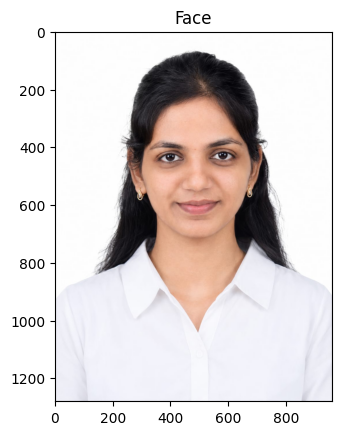

In [2]:
# Load the Face Image
faceImage = cv2.imread('th.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(1280, 959, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(1280, 959, 3)

Text(0.5, 1.0, 'glassPNG')

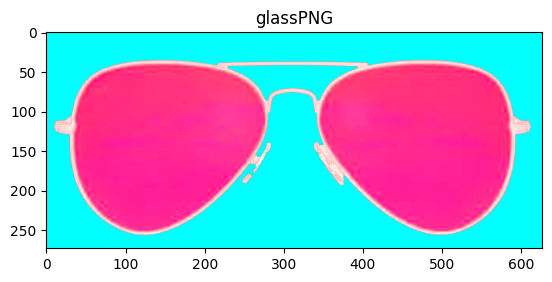

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [6]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [7]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

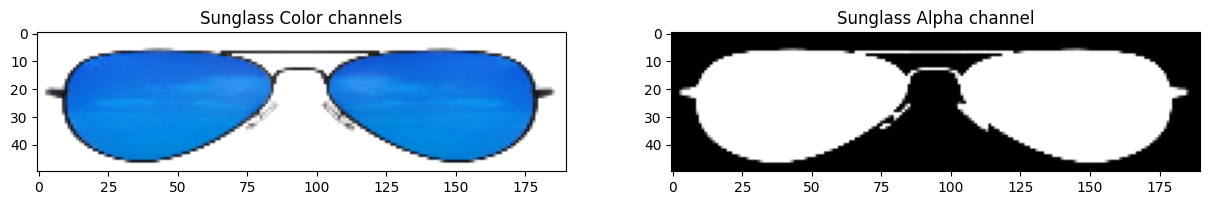

In [8]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

(np.float64(-0.5), np.float64(958.5), np.float64(1279.5), np.float64(-0.5))

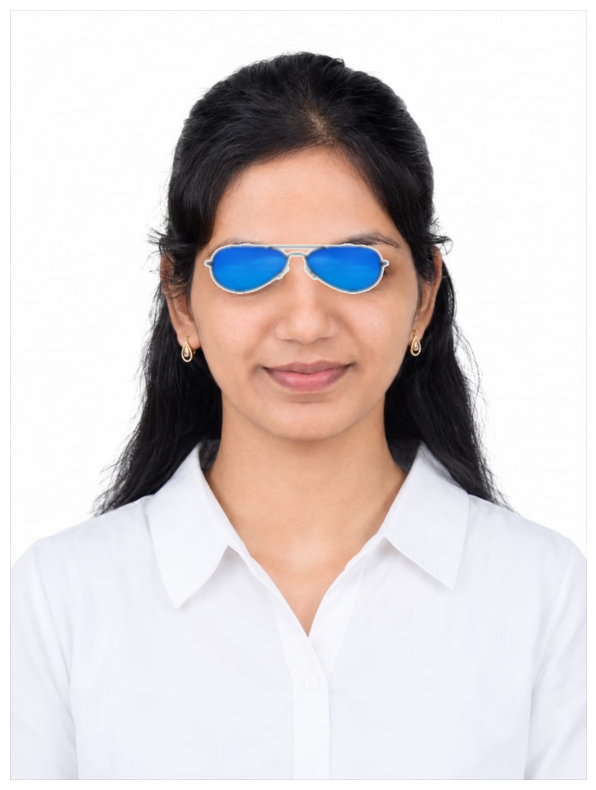

In [27]:
# Increase the specs size
glassBGR = cv2.resize(glassBGR, (315, 94))

# Make a fresh copy
faceWithGlassesNaive = faceImage.copy()

# Select the eye region
roi = faceWithGlassesNaive[380:474, 320:635]

# Create mask
mask = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY) < 245

# Place the specs
roi[mask] = glassBGR[mask]

# Display output
plt.figure(figsize=(10, 10))
plt.imshow(faceWithGlassesNaive[...,::-1])
plt.axis('off')

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

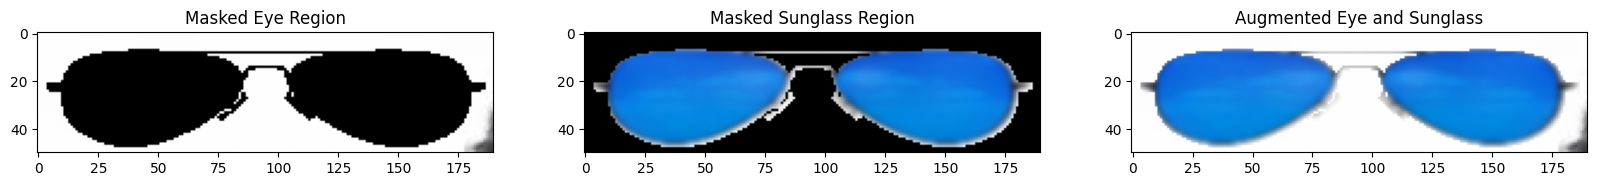

In [29]:
# Resize the mask to match the sunglasses dimensions
glassMask1 = cv2.resize(
    glassMask1,
    (glassBGR.shape[1], glassBGR.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

# Convert mask values to 0 and 1
glassMask1 = np.uint8(glassMask1 > 0)

# Convert the mask into a 3-channel image
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region
eyeROI = faceWithGlassesArithmetic[135:185, 110:300]

# Resize sunglasses to match eye ROI
glassBGR = cv2.resize(glassBGR, (190, 50))

# Resize mask again to match sunglasses
glassMask1 = cv2.resize(glassMask1, (190, 50), interpolation=cv2.INTER_NEAREST)
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Create masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Create masked sunglasses
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display results
plt.figure(figsize=(20,20))
plt.subplot(131)
plt.imshow(maskedEye[...,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[...,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeRoiFinal[...,::-1])
plt.title("Augmented Eye and Sunglass")

In [32]:
# Resize sunglasses
glassBGR = cv2.resize(glassBGR, (290, 60))

# Resize mask to match sunglasses
glassMask1 = cv2.resize(
    glassMask1, (290, 60),
    interpolation=cv2.INTER_NEAREST
)

# Convert mask values to 0 and 1
glassMask1 = np.uint8(glassMask1 > 0)

# Create 3-channel mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

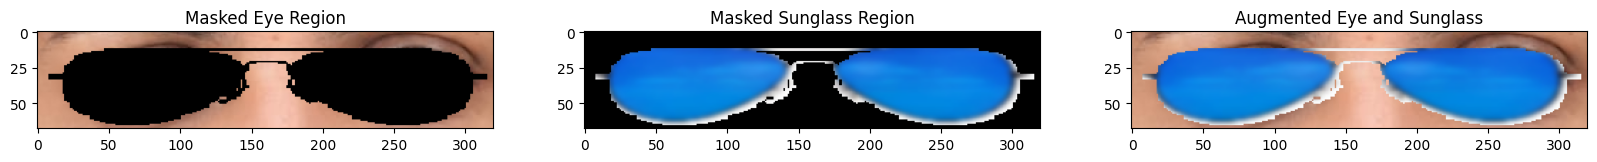

In [35]:
# Resize the sunglasses
glassBGR = cv2.resize(glassBGR, (320, 68))

# Resize the mask to match the sunglasses
glassMask1 = cv2.resize(
    glassMask1, (320, 68),
    interpolation=cv2.INTER_NEAREST
)

# Convert mask values to 0 and 1
glassMask1 = np.uint8(glassMask1 > 0)

# Convert mask into 3 channels
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Select the eye region
eyeROI = faceWithGlassesArithmetic[405:473, 318:638]

# Create masked eye region
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

# Create masked sunglasses region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both regions
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display intermediate results
plt.figure(figsize=(20,20))

plt.subplot(131)
plt.imshow(maskedEye[...,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass[...,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(eyeRoiFinal[...,::-1])
plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

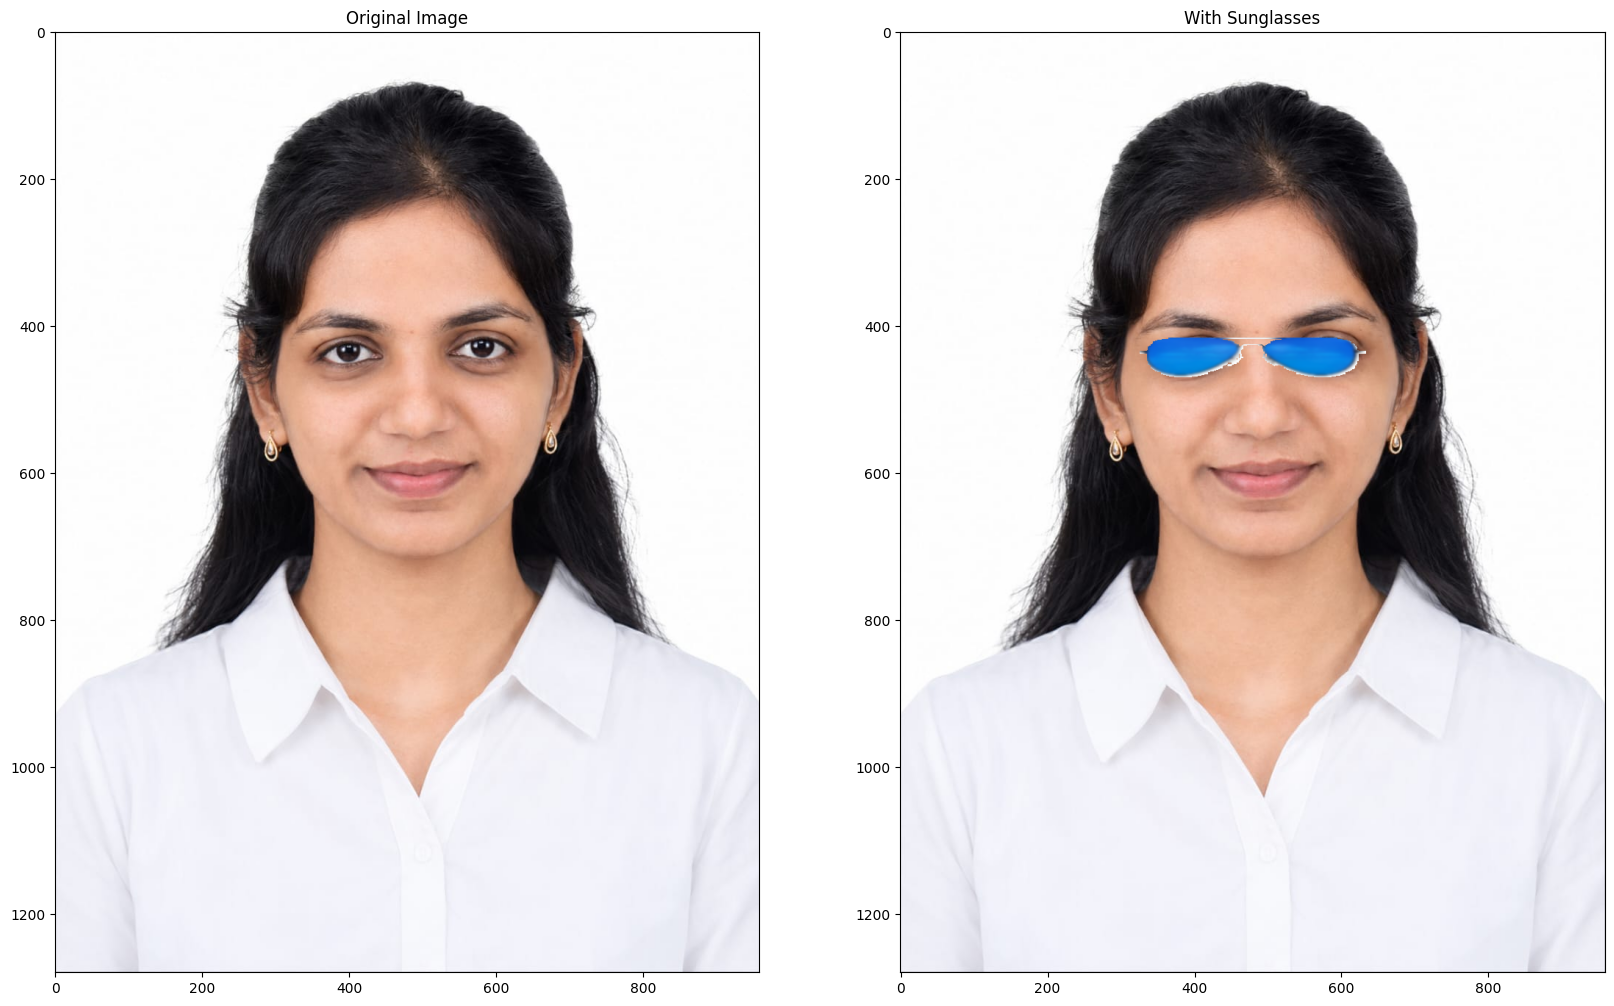

In [36]:
# Replace the eye ROI
faceWithGlassesArithmetic[405:473, 318:638] = eyeRoiFinal

# Display the result
plt.figure(figsize=(20,20))

plt.subplot(121)
plt.imshow(faceImage[...,::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[...,::-1])
plt.title("With Sunglasses")